<a href="https://colab.research.google.com/github/riyo-rep/Analisis-de-Algoritmos/blob/Cuaderno-collab-laboratorio-divide-y-venceras/EDGAR_HERNANDEZ_CASTILLO_laboratorio_divide_y_venceras_unificado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Guía de Práctica de Laboratorio: Análisis Empírico y Estructural de Algoritmos Divide y Vencerás

**Asignatura:** Análisis de Algoritmos  
**Institución:** Universidad Autónoma de Tamaulipas (Facultad de Ingeniería Tampico)  
**Unidades / Subtemas:** Unidad 2 — Subtema 2.1 (Fundamentos: MinMax y Potencia) y Subtema 2.2 (Algoritmos Clásicos de Ordenamiento: MergeSort y QuickSort)  

**Objetivos de la Práctica:**
1. **Fundamentar teóricamente el paradigma:** Comprender las fases estructurales (Dividir, Conquistar y Combinar), el planteamiento de ecuaciones de recurrencia $T(n) = aT(n/b) + f(n)$ y sus cotas asintóticas mediante consultas guiadas en NotebookLM.
2. **Contrastar estructura visual frente a ejecución real:** Evaluar la topología recursiva (mediante árboles binarios jerárquicos en Python/NetworkX) frente al comportamiento de ejecución real a nivel de hardware (mediante medición de tiempos con `timeit` en Python y `chrono` con optimización `-O3` en C++).
3. **Analizar el compromiso tiempo-espacio y las estrategias de partición:** Comparar algoritmos de *división fácil y combinación difícil* (MergeSort, estable con espacio auxiliar $O(n)$) frente a algoritmos de *división difícil y combinación trivial* (QuickSort *in-place*), verificando el impacto de la selección de pivote (primer elemento vs. Mediana de Tres) y la eliminación de recursión de cola en la profundidad de la pila de llamadas.

---

## Introducción Teórica y Contexto

En el diseño y análisis de algoritmos, la técnica **Divide y Vencerás** descompone recursivamente un problema de tamaño $n$ en $a$ subproblemas independientes más pequeños de tamaño $n/b$, los resuelve hasta alcanzar un caso base trivial y combina sus resultados con un costo adicional $f(n)$, modelado mediante la relación de recurrencia:

$$T(n) = aT\left(\frac{n}{b}\right) + f(n)$$

Dependiendo de dónde recaiga el mayor esfuerzo computacional, los algoritmos de este paradigma presentan perfiles estructurales distintos:
- **Reducción logarítmica y búsqueda simultánea:** Algoritmos como **MinMax** ($T(n) = 2T(n/2) + 2$) reducen el número de comparaciones respecto a un recorrido lineal tradicional, mientras que la **Potencia Recursiva** ($T(n) = T(n/2) + O(1)$) colapsa el árbol de llamadas a una sola rama de altura $O(\log n)$.
- **División trivial vs. Partición inteligente:** **MergeSort** divide el arreglo siempre por la mitad garantizando un rendimiento estable $\Theta(n \log n)$ en todos los casos, a costa de requerir memoria auxiliar $O(n)$ en la fase de mezcla (*merge*). En contraste, **QuickSort** realiza el trabajo pesado durante la partición *in-place*; aunque un pivote ingenuo puede degradarlo a $O(n^2)$ en arreglos ordenados o inversos, técnicas de ingenierización como la **Mediana de Tres** y el procesamiento prioritario de la partición menor acotan su complejidad esperada a $\Theta(n \log n)$ y garantizan un uso máximo de pila de $O(\log n)$.

Finalmente, la implementación dual en **Python** (interpretado, ideal para inspección estructural con `NetworkX`) y **C++** (compilado a código máquina, óptimo para benchmarks de alto volumen) permite observar el impacto tangible del costo de abstracción, las constantes ocultas y los límites de la pila de llamadas (*Call Stack*).

---

# Sección 1: Fundamentos de Divide y Vencerás — MinMax y Potencia (Subtema 2.1)

### 1.1 Guía de Autoestudio para NotebookLM (Tutor Cognitivo)

Copia y pega directamente las siguientes preguntas (*prompts*) en tu instancia de **NotebookLM**, consultando las fuentes oficiales cargadas en el notebook del curso para verificar y profundizar la precisión técnica del paradigma. <u>Tanto las preguntas como las respuestas obtenidas por la IA de NotebookLM deben transcribirse al portafolio de evidencias como notas de clase.</u>

#### Objetivo Temático 1: Comprender las Fases Estructurales e Identificación del Paradigma
* **Nivel Básico (Reconocimiento de conceptos):**
  > *"Basándote en el Capítulo IV de Gómez Fuentes & Cervantes Ojeda (UAM) y el Capítulo 4 de Baase & Van Gelder, describe con tus propias palabras cuáles son las tres fases formales del paradigma Divide y Vencerás (Dividir, Conquistar y Combinar) y qué ocurre cuando se alcanza el caso base."*
* **Nivel Intermedio (Análisis procedimental):**
  > *"A partir del texto de Lee et al. (Capítulo 4, Sección 4-1), explica paso a paso cómo se aplican las fases de Dividir, Conquistar y Combinar en el algoritmo de Búsqueda Simultánea de Mínimo y Máximo (MinMax). Detalla cuántas comparaciones exactas ahorra en comparación con el método iterativo lineal."*
* **Nivel Avanzado (Evaluación crítica y límites):**
  > *"Con base en las lecturas de la Antología UAM y el manual de la Universidad del Quindío, analiza cuál es la condición esencial respecto a la independencia de los subproblemas. ¿Por qué el algoritmo ingenuo de Fibonacci falla en ser eficiente al aplicar Divide y Vencerás y qué paradigma debe sustituirlo?"*

#### Objetivo Temático 2: Formulación Matemática y Ecuación de Recurrencia General
* **Nivel Básico (Reconocimiento de términos):**
  > *"De acuerdo con la Sección 6.7 del Manual de INACAP y la Sección 4.3 de Baase & Van Gelder, transcribe la ecuación de recurrencia general T(n) = aT(n/b) + f(n) y define qué representa cada uno de los parámetros: 'a', 'b' y 'f(n)'."*
* **Nivel Intermedio (Cálculo algebraico):**
  > *"Consulta el ejemplo del cálculo de la Potencia Recursiva x^n en el libro de la Universidad del Quindío (Capítulo 2, Sección 2.2). Explica la regla matemática para exponentes pares e impares y deriva por qué su complejidad temporal es O(log n) en lugar de O(n)."*
* **Nivel Avanzado (Rigor formal y derivación de cotas):**
  > *"Utilizando las fuentes del curso (Cormen et al. y Baase & Van Gelder), justifica cómo influye el costo de la función de combinación f(n) en el resultado final del Teorema Maestro. Proporciona un escenario donde un costo f(n) muy elevado domine la complejidad del algoritmo anulando la división."*

---

### 1.2 Laboratorio en Python: Visualización Jerárquica y Benchmark (MinMax)

*Instrucciones:* Ejecuta esta celda en Google Colab. Observa cómo la función `plot_hierarchical_tree` organiza el árbol de llamadas de manera vertical y ordenada para facilitar su conteo e inspección topológica.

=== GENERANDO ÁRBOL DE RECURSIÓN JERÁRQUICO (DIVIDE Y VENCERÁS MINMAX) ===


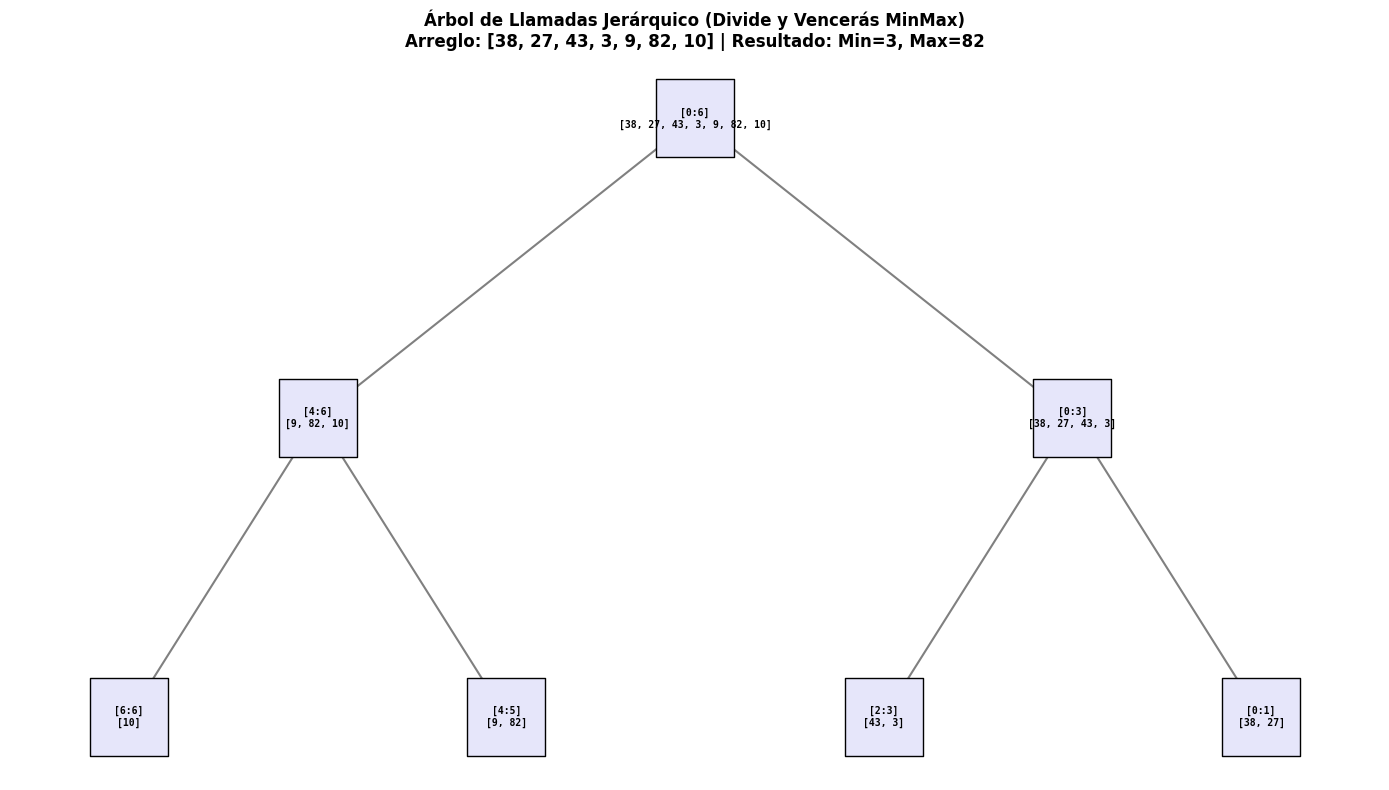


=== BENCHMARK DE RENDIMIENTO (D&C vs ITERATIVO) ===
Tiempo promedio D&C (Python):       0.043009 segundos
Tiempo promedio Iterativo (Python): 0.001079 segundos


In [ ]:
# ==============================================================================
# LABORATORIO UNIDAD 2 - DIVIDE Y VENCERÁS EN PYTHON
# ==============================================================================
import time
import timeit
import matplotlib.pyplot as plt
import networkx as nx

# ------------------------------------------------------------------------------
# 1. ALGORITMO MODELO I: BÚSQUEDA SIMULTÁNEA DE MÍNIMO Y MÁXIMO (DIVIDE Y VENCERÁS)
# ------------------------------------------------------------------------------
def minmax_divide_conquer(arr, low, high, tree_graph=None, parent_id=None):
    """
    Encuentra el mínimo y máximo de forma recursiva construyendo el árbol de llamadas.
    """
    node_id = f"[{low}:{high}]\n{arr[low:high+1]}"
    if tree_graph is not None:
        tree_graph.add_node(node_id)
        if parent_id is not None:
            tree_graph.add_edge(parent_id, node_id)

    # Caso Base 1: Un solo elemento
    if low == high:
        return (arr[low], arr[low])

    # Caso Base 2: Dos elementos
    if high == low + 1:
        if arr[low] < arr[high]:
            return (arr[low], arr[high])
        else:
            return (arr[high], arr[low])

    # FASE 1: DIVIDIR
    mid = (low + high) // 2

    # FASE 2: CONQUISTAR (Recursión)
    min1, max1 = minmax_divide_conquer(arr, low, mid, tree_graph, node_id)
    min2, max2 = minmax_divide_conquer(arr, mid + 1, high, tree_graph, node_id)

    # FASE 3: COMBINAR (2 comparaciones finales)
    global_min = min1 if min1 < min2 else min2
    global_max = max1 if max1 > max2 else max2

    return (global_min, global_max)

# ------------------------------------------------------------------------------
# 2. ALGORITMO ITERATIVO ESTÁNDAR (PARA COMPARACIÓN BENCHMARK)
# ------------------------------------------------------------------------------
def minmax_iterative(arr):
    n = len(arr)
    if n == 1:
        return (arr[0], arr[0])

    g_min = min(arr[0], arr[1])
    g_max = max(arr[0], arr[1])

    for i in range(2, n):
        if arr[i] < g_min:
            g_min = arr[i]
        elif arr[i] > g_max:
            g_max = arr[i]

    return (g_min, g_max)

# ------------------------------------------------------------------------------
# 3. VISUALIZACIÓN JERÁRQUICA LIMPIA DEL ÁRBOL DE RECURSIÓN (REUTILIZABLE)
# ------------------------------------------------------------------------------
def plot_hierarchical_tree(G, root_id, title, node_color='lavender', labels=None, sort_reverse=True):
    """
    Dibuja un grafo de NetworkX con una disposición jerárquica de árbol binario exacto,
    sin requerir Graphviz externo.
    """
    pos = {}

    def t_pos(node, x_center, y_top, width, level_height):
        pos[node] = (x_center, y_top)
        neighbors = list(G.successors(node))
        if not neighbors:
            return
        # Ordenar vecinos para garantizar consistencia izquierda/derecha
        neighbors.sort(key=lambda x: x, reverse=sort_reverse)

        # Hijo izquierdo
        t_pos(neighbors[0], x_center - width/2, y_top - level_height, width/2, level_height)
        # Hijo derecho (si existe)
        if len(neighbors) > 1:
            t_pos(neighbors[1], x_center + width/2, y_top - level_height, width/2, level_height)

    t_pos(root_id, x_center=0.5, y_top=1.0, width=0.6, level_height=0.15)

    plt.figure(figsize=(14, 8))
    if labels is None:
        labels = {n: n for n in G.nodes()}

    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15, width=1.5)
    nx.draw_networkx_nodes(G, pos, node_color=node_color, node_size=3200, edgecolors='black', node_shape='s')
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=7, font_weight='bold', font_family='monospace')

    plt.title(title, fontsize=12, fontweight='bold')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

print("=== GENERANDO ÁRBOL DE RECURSIÓN JERÁRQUICO (DIVIDE Y VENCERÁS MINMAX) ===")
G = nx.DiGraph()
sample_array = [38, 27, 43, 3, 9, 82, 10]
res_min, res_max = minmax_divide_conquer(sample_array, 0, len(sample_array) - 1, G)

root_node = [n for n, d in G.in_degree() if d == 0][0]
plot_hierarchical_tree(
    G,
    root_node,
    f"Árbol de Llamadas Jerárquico (Divide y Vencerás MinMax)\nArreglo: {sample_array} | Resultado: Min={res_min}, Max={res_max}",
    node_color='lavender',
    sort_reverse=True
)

# ------------------------------------------------------------------------------
# 4. BENCHMARKING EMPÍRICO DE TIEMPOS DE EJECUCIÓN
# ------------------------------------------------------------------------------
print("\n=== BENCHMARK DE RENDIMIENTO (D&C vs ITERATIVO) ===")
test_data = list(range(10000, 0, -1)) # 10,000 elementos inversos

t_dc = timeit.timeit(lambda: minmax_divide_conquer(test_data, 0, len(test_data)-1), number=50)
t_it = timeit.timeit(lambda: minmax_iterative(test_data), number=50)

print(f"Tiempo promedio D&C (Python):       {t_dc/50:.6f} segundos")
print(f"Tiempo promedio Iterativo (Python): {t_it/50:.6f} segundos")


### 1.3 Laboratorio en C++: Rendimiento a Nivel de Metal y Algoritmos Logarítmicos

*Instrucciones:* Ejecuta estas celdas para escribir, compilar con `g++ -O3` y ejecutar el código en C++ con $1,000,000$ de elementos, contrastando MinMax con la Potencia Recursiva en $O(\log n)$.

In [ ]:
%%writefile laboratorio_minmax.cpp
// ==============================================================================
// LABORATORIO UNIDAD 2 - DIVIDE Y VENCERÁS EN C++
// ==============================================================================
#include <iostream>
#include <vector>
#include <chrono>
#include <algorithm>

using namespace std;

// Estructura para almacenar par MinMax
struct MinMax {
    int minimo;
    int maximo;
};

// ------------------------------------------------------------------------------
// ALGORITMO MODELO I: MINMAX DIVIDE Y VENCERÁS
// ------------------------------------------------------------------------------
MinMax obtenerMinMaxDC(const vector<int>& arr, int low, int high) {
    MinMax resultado, izq, der;

    // Caso Base 1: Un elemento
    if (low == high) {
        resultado.minimo = arr[low];
        resultado.maximo = arr[low];
        return resultado;
    }

    // Caso Base 2: Dos elementos
    if (high == low + 1) {
        if (arr[low] < arr[high]) {
            resultado.minimo = arr[low];
            resultado.maximo = arr[high];
        } else {
            resultado.minimo = arr[high];
            resultado.maximo = arr[low];
        }
        return resultado;
    }

    // FASE 1: DIVIDIR
    int mid = low + (high - low) / 2;

    // FASE 2: CONQUISTAR
    izq = obtenerMinMaxDC(arr, low, mid);
    der = obtenerMinMaxDC(arr, mid + 1, high);

    // FASE 3: COMBINAR
    resultado.minimo = (izq.minimo < der.minimo) ? izq.minimo : der.minimo;
    resultado.maximo = (izq.maximo > der.maximo) ? izq.maximo : der.maximo;

    return resultado;
}

// ------------------------------------------------------------------------------
// ALGORITMO MODELO II: POTENCIA RECURSIVA X^N EN O(LOG N)
// ------------------------------------------------------------------------------
long long potenciaDC(long long x, int n) {
    if (n == 0) return 1; // Caso base

    long long subpotencia = potenciaDC(x, n / 2); // FASE DIVIDIR Y CONQUISTAR

    // FASE COMBINAR
    if (n % 2 == 0) {
        return subpotencia * subpotencia;
    } else {
        return x * subpotencia * subpotencia;
    }
}

int main() {
    cout << "==========================================================" << endl;
    cout << "    DEMOSTRACIÓN DE COMPLEJIDAD DIVIDE Y VENCERÁS EN C++   " << endl;
    cout << "==========================================================" << endl;

    // Prueba MinMax con 1,000,000 de elementos
    vector<int> datos(1000000);
    for(int i = 0; i < 1000000; ++i) datos[i] = 1000000 - i;

    auto start = chrono::high_resolution_clock::now();
    MinMax res = obtenerMinMaxDC(datos, 0, datos.size() - 1);
    auto end = chrono::high_resolution_clock::now();

    chrono::duration<double, milli> duration = end - start;
    cout << "MinMax D&C para 1,000,000 elementos:" << endl;
    cout << "   -> Minimo: " << res.minimo << " | Maximo: " << res.maximo << endl;
    cout << "   -> Tiempo de Ejecucion C++: " << duration.count() << " ms" << endl;

    // Prueba Potencia
    long long base = 2;
    int exp = 60;
    long long res_pot = potenciaDC(base, exp);
    cout << "\nPotencia Recursiva D&C (2^60): " << res_pot << " (Calculada en O(log n) pasos)" << endl;

    return 0;
}


Overwriting laboratorio_minmax.cpp


In [ ]:
!g++ -O3 laboratorio_minmax.cpp -o laboratorio_minmax && ./laboratorio_minmax

    DEMOSTRACIÓN DE COMPLEJIDAD DIVIDE Y VENCERÁS EN C++   
MinMax D&C para 1,000,000 elementos:
   -> Minimo: 1 | Maximo: 1000000
   -> Tiempo de Ejecucion C++: 3.2223 ms

Potencia Recursiva D&C (2^60): 1152921504606846976 (Calculada en O(log n) pasos)


---
# Sección 2: Algoritmos Clásicos de Ordenamiento — MergeSort y QuickSort (Subtema 2.2)

### 2.1 Guía de Autoestudio para NotebookLM (Tutor Cognitivo)

Utiliza las siguientes consultas en tu cuaderno de **NotebookLM** para analizar el comportamiento asintótico, la estabilidad y las estrategias de optimización de pila de ambos algoritmos. <u>Tanto las preguntas como las respuestas obtenidas por la IA de NotebookLM deben transcribirse al portafolio de evidencias como notas de clase.</u>

#### Objetivo Temático 1: MergeSort — Mecánica, Recurrencia y Espacio Auxiliar
* **Nivel Básico (Reconocimiento de conceptos):**
  > *"Consulta la Sección IV.7 de Gómez Fuentes & Cervantes Ojeda (UAM) y la Sección 4.6 de Baase & Van Gelder. Explica por qué MergeSort se clasifica como un algoritmo de 'división fácil y combinación difícil' y detalla la función del arreglo auxiliar `aux` en la rutina de mezcla."*
* **Nivel Intermedio (Análisis procedimental y recurrencia):**
  > *"A partir del análisis formal en la Antología UAM (pp. 77-80) y Baase (p. 175), transcribe la ecuación de recurrencia T(n) = 2T(n/2) + cn de MergeSort. Resuélvela mediante el Árbol de Recursión y explica por qué su complejidad temporal es Theta(n log n) tanto en el peor como en el mejor caso."*
* **Nivel Avanzado (Análisis de memoria y estabilidad):**
  > *"Utilizando los textos de Baase (Sección 4.6) y Gómez Fuentes, justifica por qué MergeSort es un algoritmo estable pero NO es un algoritmo in-place (requiere O(n) espacio adicional). ¿Qué ventajas y desventajas tiene frente a HeapSort?"*

#### Objetivo Temático 2: QuickSort — Estrategia de Partición, Peor/Mejor Caso y Optimizaciones
* **Nivel Básico (Reconocimiento de términos):**
  > *"Con base en la Sección 4.4 de Baase & Van Gelder y el Ejemplo 2-4 de Lee et al. (pp. 32-34), describe el procedimiento de partición en QuickSort. ¿Qué papel juega el 'pivote' y por qué la fase de combinación es trivial?"*
* **Nivel Intermedio (Análisis de peor y mejor caso):**
  > *"Basándote en el manual de INACAP (Sección 6.5) y las lecturas de la UAM (pp. 82-84), demuestra matemáticamente por qué QuickSort cae en un peor caso cuadrático O(n^2) cuando las particiones son desbalanceadas (1 vs n-1) y cómo se alcanza el mejor caso O(n log n) con particiones simétricas."*
* **Nivel Avanzado (Ingenierización y optimización de pila):**
  > *"Revisa la Sección 4.4.4 de Baase & Van Gelder ('Optimizaciones a Quicksort'). Explica detalladamente cómo la técnica de la 'Mediana de Tres' y el ordenamiento recursivo prioritario del subarreglo más pequeño limitan el uso de la pila de memoria a un máximo de O(log n)."*

---

### 2.2 Laboratorio en Python: Visualización Jerárquica de MergeSort y Profiling de QuickSort

*Instrucciones:* Ejecuta esta celda para visualizar el árbol binario jerárquico de división de **MergeSort** utilizando la misma función `plot_hierarchical_tree` de la Sección 1, y compara el rendimiento empírico entre MergeSort, QuickSort con pivote básico (`arr[0]`) y QuickSort optimizado con **Mediana de Tres** ante entradas aleatorias y entradas inversamente ordenadas (peor caso).

=== GENERANDO ÁRBOL DE RECURSIÓN JERÁRQUICO (MERGESORT) ===


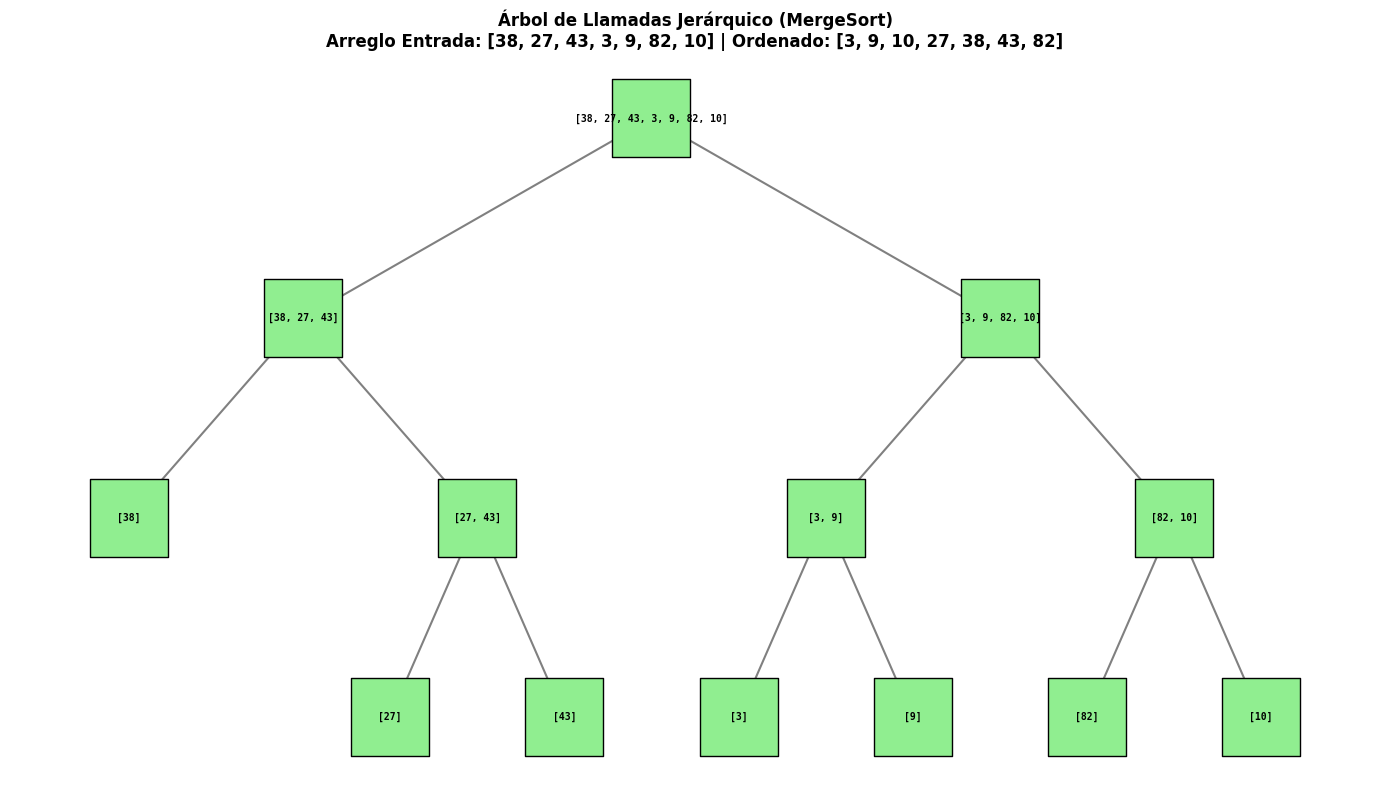


=== BENCHMARK DE RENDIMIENTO (MERGESORT VS QUICKSORT BÁSICO VS MEDIANA DE 3) ===
Datos Aleatorios (n = 5,000):
   -> MergeSort:                   0.02617 seg
   -> QuickSort (Pivote 1er elem): 0.01453 seg
   -> QuickSort (Mediana de 3):    0.01527 seg

Datos Inversamente Ordenados (n = 2,000 - Escenario Peor Caso):
   -> MergeSort (Estable Theta(n log n)):           0.00581 seg
   -> QuickSort (Pivote 1er elem - Peor Caso O(n^2)): 0.22555 seg
   -> QuickSort (Mediana de 3 - Mitigado O(n log n)): 0.00261 seg


In [ ]:
# ==============================================================================
# LABORATORIO UNIDAD 2 - MERGESORT Y QUICKSORT EN PYTHON
# ==============================================================================
import sys
import timeit
import random
import matplotlib.pyplot as plt
import networkx as nx

# ------------------------------------------------------------------------------
# 1. IMPLEMENTACIÓN DE MERGESORT
# ------------------------------------------------------------------------------
def merge_sort(arr):
    if len(arr) <= 1:
        return arr

    mid = len(arr) // 2
    left = merge_sort(arr[:mid])
    right = merge_sort(arr[mid:])

    return merge(left, right)

def merge(left, right):
    result = []
    i = j = 0
    while i < len(left) and j < len(right):
        if left[i] <= right[j]:  # Preserva estabilidad
            result.append(left[i])
            i += 1
        else:
            result.append(right[j])
            j += 1
    result.extend(left[i:])
    result.extend(right[j:])
    return result

# ------------------------------------------------------------------------------
# 2. IMPLEMENTACIÓN DE QUICKSORT (PIVOTE PRIMER ELEMENTO Y MEDIANA DE 3)
# ------------------------------------------------------------------------------
def quicksort_basic(arr):
    """QuickSort básico utilizando el primer elemento (arr[0]) como pivote."""
    if len(arr) <= 1:
        return arr
    pivot = arr[0]
    less = [x for x in arr[1:] if x <= pivot]
    greater = [x for x in arr[1:] if x > pivot]
    return quicksort_basic(less) + [pivot] + quicksort_basic(greater)

def quicksort_median3(arr):
    """QuickSort optimizado con pivote Mediana de Tres."""
    if len(arr) <= 1:
        return arr

    first = arr[0]
    middle = arr[len(arr) // 2]
    last = arr[-1]

    # Elección de la mediana de los tres candidatos
    pivot = sorted([first, middle, last])[1]

    # Partición alrededor de la mediana
    arr_copy = arr.copy()
    arr_copy.remove(pivot)
    less = [x for x in arr_copy if x <= pivot]
    greater = [x for x in arr_copy if x > pivot]

    return quicksort_median3(less) + [pivot] + quicksort_median3(greater)

# ------------------------------------------------------------------------------
# 3. VISUALIZACIÓN JERÁRQUICA DEL ÁRBOL DE RECURSIÓN (MERGESORT)
# ------------------------------------------------------------------------------
def build_mergesort_tree(arr, graph=None, parent=None, depth=0, branch="0"):
    if graph is None:
        graph = nx.DiGraph()

    # El prefijo D{depth}_{branch} mantiene el orden estricto Izquierda (0) -> Derecha (1)
    node_id = f"D{depth}_{branch}\n{str(arr)}"
    graph.add_node(node_id, label=str(arr))

    if parent:
        graph.add_edge(parent, node_id)

    if len(arr) > 1:
        mid = len(arr) // 2
        build_mergesort_tree(arr[:mid], graph, node_id, depth + 1, "0_Izq")
        build_mergesort_tree(arr[mid:], graph, node_id, depth + 1, "1_Der")

    return graph

print("=== GENERANDO ÁRBOL DE RECURSIÓN JERÁRQUICO (MERGESORT) ===")
sample_data = [38, 27, 43, 3, 9, 82, 10]
G_merge = build_mergesort_tree(sample_data)
root_merge = [n for n, d in G_merge.in_degree() if d == 0][0]
merge_labels = nx.get_node_attributes(G_merge, 'label')

# Se reutiliza plot_hierarchical_tree (definida en la Sección 1.2)
if 'plot_hierarchical_tree' in globals():
    plot_hierarchical_tree(
        G_merge,
        root_merge,
        f"Árbol de Llamadas Jerárquico (MergeSort)\nArreglo Entrada: {sample_data} | Ordenado: {merge_sort(sample_data)}",
        node_color='lightgreen',
        labels=merge_labels,
        sort_reverse=False
    )
else:
    print("Nota: Ejecuta primero la celda de la Sección 1.2 para cargar plot_hierarchical_tree.")

# ------------------------------------------------------------------------------
# 4. BENCHMARKING DE TIEMPOS DE EJECUCIÓN (MERGESORT VS QUICKSORT)
# ------------------------------------------------------------------------------
print("\n=== BENCHMARK DE RENDIMIENTO (MERGESORT VS QUICKSORT BÁSICO VS MEDIANA DE 3) ===")
random_data = [random.randint(1, 100000) for _ in range(5000)]
reverse_data = list(range(2000, 0, -1))  # Peor caso potencial para pivote arr[0]

t_ms_rand = timeit.timeit(lambda: merge_sort(random_data), number=10)
t_qs_rand = timeit.timeit(lambda: quicksort_basic(random_data), number=10)
t_qs_m3_rand = timeit.timeit(lambda: quicksort_median3(random_data), number=10)

print(f"Datos Aleatorios (n = 5,000):")
print(f"   -> MergeSort:                   {t_ms_rand/10:.5f} seg")
print(f"   -> QuickSort (Pivote 1er elem): {t_qs_rand/10:.5f} seg")
print(f"   -> QuickSort (Mediana de 3):    {t_qs_m3_rand/10:.5f} seg")

sys.setrecursionlimit(5000)  # Prevenir RecursionError en el peor caso O(n^2)
t_ms_rev = timeit.timeit(lambda: merge_sort(reverse_data), number=5)
t_qs_rev = timeit.timeit(lambda: quicksort_basic(reverse_data), number=5)
t_qs_m3_rev = timeit.timeit(lambda: quicksort_median3(reverse_data), number=5)

print(f"\nDatos Inversamente Ordenados (n = 2,000 - Escenario Peor Caso):")
print(f"   -> MergeSort (Estable Theta(n log n)):           {t_ms_rev/5:.5f} seg")
print(f"   -> QuickSort (Pivote 1er elem - Peor Caso O(n^2)): {t_qs_rev/5:.5f} seg")
print(f"   -> QuickSort (Mediana de 3 - Mitigado O(n log n)): {t_qs_m3_rev/5:.5f} seg")


### 2.3 Laboratorio en C++: MergeSort con Memoria Auxiliar vs. QuickSort In-Place Optimizado

*Instrucciones:* Ejecuta las siguientes dos celdas para compilar con `g++ -O3` y comparar el rendimiento sobre $500,000$ elementos entre **MergeSort** (con reserva dinámica de vectores `L` y `R`) y **QuickSort Optimizado** (*in-place*, Mediana de Tres, inserción directa para subarreglos menores a 10 elementos y eliminación de recursión de cola).

In [ ]:
%%writefile laboratorio_mergesort_quicksort.cpp
// ==============================================================================
// LABORATORIO UNIDAD 2 - MERGESORT Y QUICKSORT EN C++
// ==============================================================================
#include <iostream>
#include <vector>
#include <chrono>
#include <algorithm>
#include <cstdlib>

using namespace std;

// ------------------------------------------------------------------------------
// 1. MERGESORT CON MEMORIA DINÁMICA AUXILIAR
// ------------------------------------------------------------------------------
void mezclar(vector<int>& A, int ini, int med, int fin) {
    int n1 = med - ini + 1;
    int n2 = fin - med;

    vector<int> L(n1), R(n2);
    for (int i = 0; i < n1; i++) L[i] = A[ini + i];
    for (int j = 0; j < n2; j++) R[j] = A[med + 1 + j];

    int i = 0, j = 0, k = ini;
    while (i < n1 && j < n2) {
        if (L[i] <= R[j]) {
            A[k] = L[i];
            i++;
        } else {
            A[k] = R[j];
            j++;
        }
        k++;
    }
    while (i < n1) { A[k] = L[i]; i++; k++; }
    while (j < n2) { A[k] = R[j]; j++; k++; }
}

void mergeSort(vector<int>& A, int ini, int fin) {
    if (ini < fin) {
        int med = ini + (fin - ini) / 2;
        mergeSort(A, ini, med);
        mergeSort(A, med + 1, fin);
        mezclar(A, ini, med, fin);
    }
}

// ------------------------------------------------------------------------------
// 2. QUICKSORT IN-PLACE CON MEDIANA DE TRES Y OPTIMIZACIÓN DE PILA
// ------------------------------------------------------------------------------
int particionMediana3(vector<int>& A, int low, int high) {
    int mid = low + (high - low) / 2;

    // Seleccionar mediana entre low, mid, high
    if (A[mid] < A[low]) swap(A[low], A[mid]);
    if (A[high] < A[low]) swap(A[low], A[high]);
    if (A[high] < A[mid]) swap(A[mid], A[high]);

    // Colocar el pivote en high - 1 para ejecutar la partición estándar
    swap(A[mid], A[high - 1]);
    int pivot = A[high - 1];

    int i = low;
    int j = high - 1;

    for (;;) {
        while (A[++i] < pivot) {}
        while (pivot < A[--j]) {}
        if (i >= j) break;
        swap(A[i], A[j]);
    }
    swap(A[i], A[high - 1]);
    return i;
}

void quickSortOptimizado(vector<int>& A, int low, int high) {
    while (low < high) {
        // Para subarreglos pequeños (< 10), usar ordenamiento por inserción
        if (high - low < 10) {
            for (int i = low + 1; i <= high; i++) {
                int key = A[i];
                int j = i - 1;
                while (j >= low && A[j] > key) {
                    A[j + 1] = A[j];
                    j--;
                }
                A[j + 1] = key;
            }
            break;
        } else {
            int p = particionMediana3(A, low, high);

            // Optimización de Pila: Procesar recursivamente la partición menor primero
            if (p - low < high - p) {
                quickSortOptimizado(A, low, p - 1);
                low = p + 1; // Iterar sobre la partición derecha (Tail Recursion Elimination)
            } else {
                quickSortOptimizado(A, p + 1, high);
                high = p - 1; // Iterar sobre la partición izquierda
            }
        }
    }
}

int main() {
    cout << "==========================================================" << endl;
    cout << "  BENCHMARK DE RENDIMIENTO MERGESORT VS QUICKSORT EN C++  " << endl;
    cout << "==========================================================" << endl;

    const int N = 500000;
    vector<int> datos1(N), datos2(N);

    srand(42);
    for (int i = 0; i < N; i++) {
        int val = rand() % 1000000;
        datos1[i] = val;
        datos2[i] = val;
    }

    // Benchmark MergeSort
    auto start1 = chrono::high_resolution_clock::now();
    mergeSort(datos1, 0, N - 1);
    auto end1 = chrono::high_resolution_clock::now();
    chrono::duration<double, milli> d1 = end1 - start1;

    // Benchmark QuickSort Optimizado
    auto start2 = chrono::high_resolution_clock::now();
    quickSortOptimizado(datos2, 0, N - 1);
    auto end2 = chrono::high_resolution_clock::now();
    chrono::duration<double, milli> d2 = end2 - start2;

    cout << "Prueba sobre " << N << " elementos desordenados:" << endl;
    cout << "   -> MergeSort Tiempo C++:             " << d1.count() << " ms" << endl;
    cout << "   -> QuickSort Optimizado Tiempo C++:  " << d2.count() << " ms" << endl;
    cout << "\nVerificación de Ordenamiento: "
         << (is_sorted(datos1.begin(), datos1.end()) && is_sorted(datos2.begin(), datos2.end()) ? "EXITOSA" : "FALLIDA")
         << endl;

    return 0;
}


Overwriting laboratorio_mergesort_quicksort.cpp


In [ ]:
!g++ -O3 laboratorio_mergesort_quicksort.cpp -o laboratorio_mq && ./laboratorio_mq

  BENCHMARK DE RENDIMIENTO MERGESORT VS QUICKSORT EN C++  
Prueba sobre 500000 elementos desordenados:
   -> MergeSort Tiempo C++:             92.5549 ms
   -> QuickSort Optimizado Tiempo C++:  45.6354 ms

Verificación de Ordenamiento: EXITOSA


---
# Sección Final: Bitácora de Reporte del Alumno(a)

**Nombre del Alumno(a):** Hernández Castillo Edgar **Matrícula:** a2231330034  
**Grupo:** K **Fecha de Entrega:** 26/11/26

---

## Parte I: Evaluación de la Sesión 1 — Fundamentos, MinMax y Potencia (Subtema 2.1)

### Fase 1: Inspección Topológica del Árbol de Recursión (Python & NetworkX)

1. **Conteo por Niveles (Arreglo `[38, 27, 43, 3, 9, 82, 10]`):**
   - Niveles de profundidad generados: **3**  
   - Nodos en el Nivel 1: **2** | Nodos en el Nivel de Hojas (casos base): **4**

2. **Pregunta de Análisis:** Observa las etiquetas de los rangos en los nodos hijos (ej. `[0:6]` se divide en `[0:3]` y `[4:6]`). ¿La división de los subarreglos siempre es simétrica? ¿Cómo afecta el redondeo de la división entera (`// 2`) a la geometría del árbol?
   > *[No siempre es simétrica. Solo se parte exactamente igual cuando el tamaño del arreglo es par y todo el árbol queda parejo solo si es potencia de 2. Cuando el tamaño es impar, como con 7 elementos en [0:6], no se puede dividir en mitades iguales y por la división entera (/2) el lado izquierdo siempre se queda con un elemento más. Esto hace que en el árbol la rama izquierda quede un poco más cargada que la derecha, aunque como la diferencia es nada más de un elemento por división, el árbol sigue quedando algo balanceado. ]*

### Fase 2: Benchmark de Rendimiento y Escalamiento MinMax (Python vs. C++)

Completa la tabla comparativa con los datos obtenidos al ejecutar los scripts de la Sección 1:

| Lenguaje / Entorno | Algoritmo | Tamaño de Entrada ($n$) | Ejecuciones | Tiempo Registrado | Observaciones de Estabilidad |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Python** (`timeit`) | D&C MinMax | $10,000$ | 50 iteraciones | 0.43009s| |
| **Python** (`timeit`) | Iterativo MinMax | $10,000$ | 50 iteraciones |0.001079s | |
| **C++** (`chrono`) | D&C MinMax | $1,000,000$ | 1 ejecución |3.2223s |O(log n) pasos|

- **Pregunta de Análisis:** Si intentaras ejecutar el caso de $n = 1,000,000$ utilizando la función recursiva de Python en la misma máquina, ¿qué cuello de botella técnico frenaría la ejecución primero y por qué?
  > *[Lo primero que frenaría la ejecución no sería el límite de recursión, sino el tiempo de CPU por la enorme cantidad de llamadas recursivas. Aunque la profundidad sea poca, en total se hacen entre 1 y 2 millones de llamadas a la función. Como Python es interpretado, cada llamada tiene que crear y manejar un marco en la pila, lo cual cuesta bastante tiempo y hace que el programa se vuelva muy lento comparado con C++.]*

### Fase 3: Análisis de Complejidades Distintas en C++ (MinMax vs. Potencia)

- **Pregunta de Análisis:** Explica por qué el árbol de llamadas de `potenciaDC(2, 60)` tiene una altura de apenas $\approx 6$ niveles (crecimiento logarítmico), a diferencia del árbol de MinMax. ¿Cómo se refleja esta diferencia en el consumo de memoria del *Call Stack*?
  > *[En potenciaDC(2, 60) el exponente se va dividiendo entre 2 en cada paso y solo se hace una llamada recursiva por nivel porque el resultado se reutiliza. En el Call Stack esto se refleja en que casi no consume memoria, ya que como máximo llega a apilar 6 llamadas al mismo tiempo. En cambio, MinMax hace dos llamadas por nivel y, aunque también libera memoria al ir regresando de cada rama, con arreglos grandes alcanza más profundidad y realiza millones de llamadas en la pila.]*

---

## Parte II: Evaluación de la Sesión 2 — MergeSort y QuickSort (Subtema 2.2)

### Fase 4: Comparación Topológica (Árbol de MinMax vs. Árbol de MergeSort)

1. **Inspección del Árbol de MergeSort (`[38, 27, 43, 3, 9, 82, 10]`):**
   - Total de nodos generados en MergeSort: **13** | Total de nodos hojas (tamaño 1): **7**

2. **Pregunta de Análisis:** Compara los dos árboles jerárquicos generados en Python para el mismo arreglo de 7 elementos. ¿Por qué el árbol de MergeSort tiene mayor profundidad y más nodos hoja que el árbol de MinMax?
   > *[La diferencia está en el caso base de cada algoritmo. En MinMax la recursión se puede detener cuando el subarreglo tiene tamaño 1 o tamaño 2. En cambio, MergeSort tiene que seguir dividiendo hasta que todos los subarreglos sean de tamaño 1 para poder empezar a mezclarlos en orden.]*

### Fase 5: Impacto del Pivote y Escenario de Peor Caso (Python)

Registra los tiempos promedio obtenidos al ejecutar el benchmark de la Sección 2.2:

| Algoritmo (Python) | Datos Aleatorios ($n = 5,000$) | Datos Inversos ($n = 2,000$) | Comportamiento Asintótico Observado |
| :--- | :--- | :--- | :--- |
| **MergeSort** |0.02617s |0.00581s | Estable theta(n log n) |
| **QuickSort** (Pivote `arr[0]`) | 0.01453 s|0.22555s | Peor caso O(n^2)|
| **QuickSort** (Mediana de Tres) |0.01527s | 0.00261s| Mitigado O(n log n)|

- **Pregunta de Análisis:** Explica por qué `quicksort_basic` sufrió una degradación severa con `reverse_data` ($n = 2,000$) y requirió ampliar el límite de recursión (`sys.setrecursionlimit(5000)`), mientras que `quicksort_median3` mantuvo un tiempo cercano a $O(n \log n)$.
  > *[En quicksort, como siempre elige el primer elemento (arr[0]) como pivote y los datos están al revés, el pivote siempre termina siendo el valor más grande. Esto hace que las particiones queden completamente desbalanceadas (un lado con $n - 1$ elementos y el otro vacío), degradando el tiempo a $O(n^2)$ y generando 2,000 llamadas recursivas seguidas. ]*

### Fase 6: Compromiso Tiempo-Espacio y Optimización de Pila en C++ ($n = 500,000$)

Registra los tiempos obtenidos en la ejecución compilada de la Sección 2.3:

| Algoritmo (C++ `-O3`) | Tamaño ($n$) | Tiempo Registrado (`ms`) | Complejidad Espacial Auxiliar |
| :--- | :--- | :--- | :--- |
| **MergeSort** (`mezclar` con vectores `L` y `R`) | $500,000$ |92.5549 ms | $O(n)$ |
| **QuickSort Optimizado** (*In-Place* + Mediana de 3) | $500,000$ |45.6354 ms| $O(\log n)$ en pila |

- **Pregunta de Análisis:** Aunque ambos algoritmos poseen complejidad temporal promedio $\Theta(n \log n)$, ¿qué factores de arquitectura de memoria (asignación dinámica en el *Heap* en `mezclar` frente a localidad de caché *in-place* y eliminación de recursión de cola en `quickSortOptimizado`) explican la diferencia de velocidad observada en C++?
  > *[MergeSort: En cada llamada a mezclar tiene que pedir y liberar memoria dinámica en el Heap para crear los vectores auxiliares L y R, además de estar copiando todos los elementos de ida y vuelta, lo que agrega bastante tiempo extra.
  
  QuickSort Optimizado: Ordena los datos in-place sobre el mismo arreglo, lo que aprovecha mucho mejor la memoria caché del procesador al leer posiciones seguidas. Además, al usar eliminación de recursión de cola (procesando la partición más grande con un ciclo while), se ahorra llamadas en la pila y el compilador con -O3 lo optimiza mejor.]*

### Formato de Entrega / Portafolio de Evidencias
1. Guarda este cuaderno con todas las salidas ejecutadas incluyendo las respuesta a las preguntas (`Archivo` -> `Guardar una copia en Drive`).
2. Sube los cambios a tu repositorio de GitHub de la materia bajo el nombre `JUAN PEREZ laboratorio_divide_y_venceras.ipynb` usando la integración directa (`Archivo` -> `Guardar una copia en GitHub`).
3. Adjunta en tu entregable de plataforma Moodle, el enlace de GitHub.